# Stokes: a synthetic polarization image

The polarization of light at a pixel is described by its **Stokes vector**
`[S0, S1, S2, S3]`:

- S0 is the total intensity;
- S1 compares horizontal and vertical polarization, S2 compares +45° and −45°;
- S3 measures circular polarization, its sign giving the handedness.

A Stokes vector is physically valid when S0 ≥ √(S1² + S2² + S3²): the polarized part
cannot be brighter than the light itself. The **Stokes** model writes a polarization image
as a sum of terms *non-negative spatial map × valid Stokes vector*
(see [Stokes](../models/stokes.md)).

## The data

25 × 25 pixels and R = 3 terms with spatial maps of rank L = 2.
{meth}`~pybbtd.stokes.Stokes.generate_stokes_tensor` draws random non-negative spatial
factors and one random fully polarized state per term. We add 1% noise.

In [1]:
import numpy as np

from pybbtd import Stokes
from pybbtd.stokes import is_valid_stokes, validate_stokes_tensor
from pybbtd.visualization import plot_error

np.random.seed(0)
model = Stokes((25, 25), R=3, L=2)
(A0, B0, C0), T0 = model.generate_stokes_tensor()
T = T0 + 0.01 * np.linalg.norm(T0) / np.sqrt(T0.size) * np.random.randn(*T0.shape)

Each true state is fully polarized, but every pixel mixes the three of them, which makes
it partially polarized and puts it well inside the valid set. Both the clean and the noisy
data are valid everywhere:

In [2]:
print("clean data valid:", validate_stokes_tensor(T0))
print("noisy data valid:", validate_stokes_tensor(T))

clean data valid: True
noisy data valid: True


## Fit the model

The AO-ADMM solver keeps the spatial maps non-negative and every Stokes vector valid.
The K-means initialization groups pixels with similar Stokes vectors.

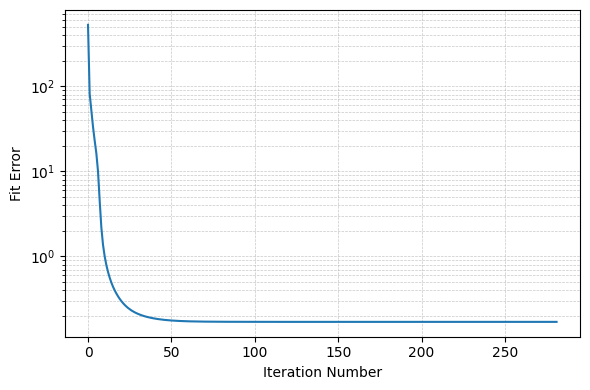

In [3]:
model.fit(T, init="kmeans", max_iter=5000, rel_tol=1e-10, abs_tol=0)
plot_error(model.fit_error)

## Check the result

The recovered Stokes vectors, scaled to S0 = 1, next to the true ones (the order of the
terms can differ):

In [4]:
np.set_printoptions(precision=3, suppress=True)
A, B, C = model.factors
print("true:\n", C0 / C0[0])
print("recovered:\n", C / C[0])
print("all valid:", all(is_valid_stokes(c) for c in C.T))

true:
 [[ 1.     1.     1.   ]
 [ 0.551  0.696 -0.157]
 [ 0.726  0.348 -0.944]
 [-0.413  0.628 -0.29 ]]
recovered:
 [[ 1.     1.     1.   ]
 [-0.156  0.551  0.695]
 [-0.945  0.725  0.347]
 [-0.289 -0.413  0.63 ]]
all valid: True


The fitted tensor is closer to the clean image than the noisy data are (1% away):

In [5]:
np.linalg.norm(model.tensor - T0) / np.linalg.norm(T0)

np.float64(0.0031636588618997106)